In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

from msolver import IASGKS, MMGKS, VanillaGKS

# Setup toy problem

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)

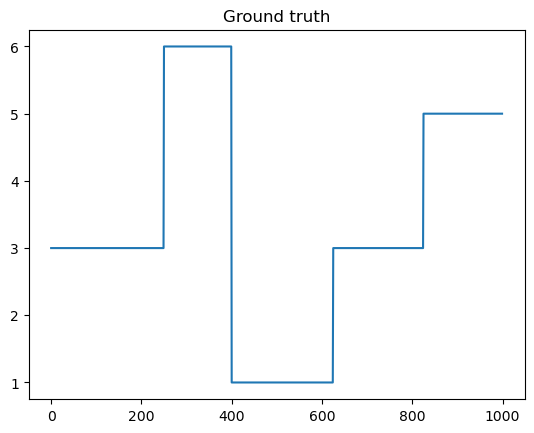

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

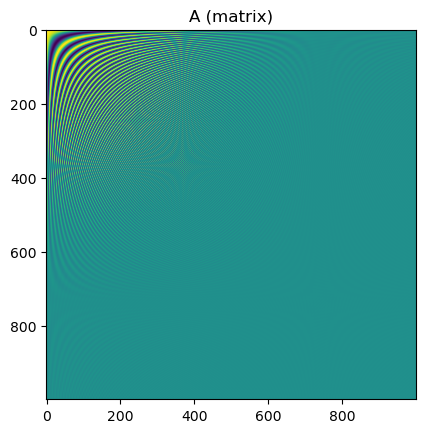

In [6]:
plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [203]:
# # Random undersampling
# np.random.seed(0)
# mask = np.random.binomial(1, 0.8, size=n)
# P = jlinops.Subsampling1DOperator(mask)

# Only first 100 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

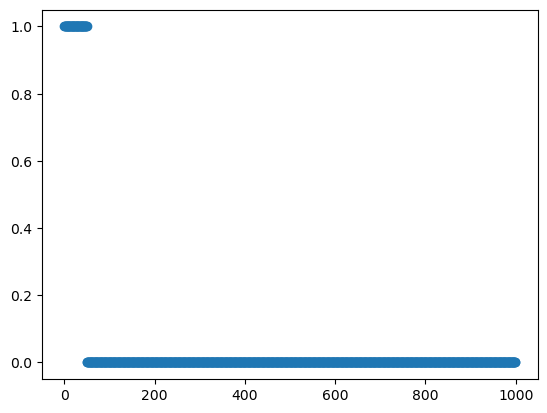

In [204]:
plt.scatter(grid, mask)
plt.show()

In [205]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

In [206]:
noise_var

0.2514573489857872

In [207]:
# # Inverse DCT reconstruction
# plt.plot(A.T @ b)
# plt.plot(ground_truth, color="k")
# plt.show()

In [208]:
# # # Other way of generating the data

# # Generate synthetic data
# np.random.seed(0)
# A = P @ F
# b_true = A @ ground_truth
# noise_sigma = 0.2
# b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])
# noise_var = noise_sigma**2

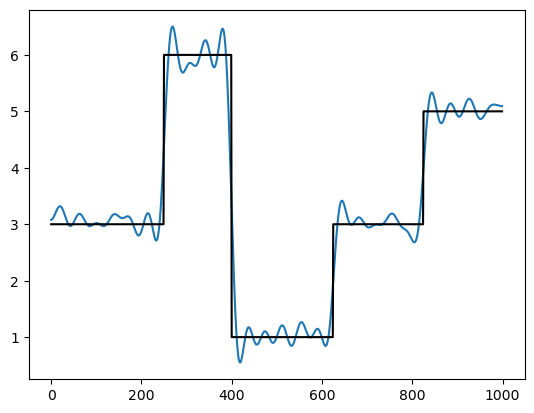

In [209]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [210]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
Kmat = Kmat/np.linalg.norm(Kmat)

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator


# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)
K

#err_norm_sq = len(b) # in expectation

# Build solvers

q = 1.0
epsilon = 1e-4
mmgks_weight_params = {
    "q": q,
    "epsilon": epsilon,
}

gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b)

# Run all methods

In [211]:
n_its = 200
method = "dp"

vpdata = gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params={}, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished L2 GKS (priorconditioned)")

vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)
print("Finished L2 GKS (vanilla)")

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=mmgks_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
print("Finished S-GKS (priorconditioned)")

data = mmgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
print("Finished S-GKS (vanilla)")

resdata = mmgks_solver.solve(n_iter=200, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker, restart_dim=30)
print("Finished S-GKS (restarted)")


recdata = mmgks_solver.solve(n_iter=200, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=mmgks_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=15, max_dim=30, xker=xker, restart_dim=None)
print("Finished S-GKS (recycling)")

1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
31.62319095539862
116.24592604025442
131.9758275702863
139.30801128708316
141.62733364738875
143.01885429086008
143.3788125638155
143.4830559244382
143.5076428188278
143.51449535809328
143.51610550832717
143.5163801700576
143.5164577106791
143.51647445330914
143.51647660475527
143.51647693212198
143.5164770082982
143.5164770162038
143.51647701729678
143.51647701743534
143.51647701744437
143.5164770174447
143.51647701744477
143.5164770174449
143.51647701744486
143.51647701744488
143.5164770174449
143.51647701744488
143.5164770174449
143.51647701744474
143.51647701744477
143.51647701744486
143.51647701744483
143.51647701744474
143.51647701744466
143.51647701744477
143.51647701744477
143.51647701744486
143.5164770174449
143.51647701744452
143.51647701744486
143.51647701744486
143.51647701744483
143.51647701744488
143.5164770174449
143.51647701744486
143.51647701744488
143.5164770174448
143.51647701744486
143.51647701744486
143.51647701744486
143.5164770

712.4352939343164
313.37688956665164
173.65850933017586
160.22316437180504
156.42683371661784
154.5182676308331
153.02692623933018
151.53095534516513
149.85582845753214
148.28508304070328
147.03265125815278
146.16390266639357
145.5579899324737
145.11634310699793
144.7776471164702
144.49582192950552
144.2765757634909
144.09680125755997
143.95377910532878
143.83566235329278
143.7421485449182
143.67958142370674
143.63150284563577
143.59602087803415
143.57101709999938
143.55184798233
143.53864453656294
143.52944053731824
143.5226257228036
143.51812172305557
143.5151546915997
143.51349734228555
143.51286739220728
143.51275201379985
143.51298594693645
143.51342217547386
143.51391147873576
143.51437853738582
143.51482640259647
143.51525087768073
143.51557453481388
143.51585608698917
143.51607582590736
143.51622167901527
143.5163353229858
143.51643068333658
143.51649608465053
143.51653867376675
143.51656341196082
143.51657662998304
143.5165808589555
143.51657785191722
143.51656911946577
143.51

1e-07
9.152249063987906
12.124848631952299
13.898700397613771
14.937625662829022
15.468317982564775
15.882136713248832
16.355915814083982
16.764000216033047
17.181340881511236
17.58926032865126
17.977569629078484
18.37157687065222
18.739434477200792
19.095178655020646
19.432599254313164
19.75227600499657
20.05134604876726
20.332771709634777
20.59396341563322
20.833913977382025
21.057134719132225
21.263447884726734
21.454404839766713
21.631885900381835
21.797142142315113
21.95104398280325
22.09494030629391
22.229770867184012
22.35637627547815
22.47552358160783
22.587908926243916
22.694115769918817
22.794658916189174
22.890027988705345
22.980622953627655
23.066805623122843
23.14889718944517
23.227193324652006
23.301946259557702
23.373393028494295
23.44174755659456
23.507200585951836
23.56992956910151
23.63009901386974
23.687860432556857
23.743349937837888
23.796699676567233
23.84802874071885
23.897448993769384
23.945064663328658
23.99097303773014
24.035263705668168
24.078021569089447
24.

7.854499470273605
7.775419084736617
8.929620157204033
8.412119251519414
8.886904525326802
9.088498709068073
10.004481883014314
9.691885757941183
10.233205654719756
10.669386030072191
10.956825313904908
11.189911468402043
11.266347598708775
11.638113088242774
10.684725068874279
10.479304945820362
11.059581470362216
10.509934066603542
10.512087360672876
9.553274435607094
9.719455434180873
9.866580170948536
10.125454894637615
10.083722174766764
9.784915902459906
9.810907422538795
10.465748327998318
10.898250176106975
11.115289011202995
10.765666531466275
11.118899143977472
11.40750081757693
11.77474189311646
11.792152895576294
11.702498617465267
12.17802591725997
12.73649791595801
13.418808757389066
14.120215037865467
14.854808717435256
15.861568485530649
16.23449252413167
16.58844762392986
17.178142843864574
18.055647506457497
18.9750293284803
20.399027741159646
21.20089302694586
21.32604643579912
21.86063492667841
22.90838332318017
23.983061611934755
25.50431061177837
27.07380508222008


7.854499470273605
7.775419084736617
8.929620157204033
8.412119251519414
8.886904525326802
9.088498709068073
10.004481883014314
9.691885757941183
10.233205654719756
10.669386030072191
10.956825313904908
11.189911468402043
11.266347598708775
11.638113088242774
10.684725068874279
10.479304945820362
11.059581470362216
10.509934066603542
10.512087360672876
9.553274435607094
9.719455434180873
9.866580170948536
10.125454894637615
10.083722174766764
10.076494093568508
11.218572628237393
12.130127011802108
12.855153107742229
13.396551686410527
13.891952806535949
14.20577327850336
14.282280099662534
13.65266413187227
13.081823121267634
11.309132147540039
10.198321859334728
9.558313670319578
9.772271252822897
10.855871771688097
11.767661643981064
13.06164863208409
13.902641128606358
13.815708572998346
12.489495338595766
10.598274520758405
8.585514554073203
7.815081206937889
8.413255835199525
9.560803949845136
10.923906009837186
10.862469271316371
10.210463422441642
9.810335244954246
9.80554820970

7.854499470273605
7.775419084736617
8.929620157204033
8.412119251519414
8.886904525326802
9.088498709068073
10.004481883014314
9.691885757941183
10.233205654719756
10.669386030072191
10.956825313904908
11.189911468402043
11.266347598708775
11.638113088242774
10.684725068874279
10.479304945820362
11.059581470362216
10.509934066603542
10.512087360672876
9.553274435607094
9.719455434180873
9.866580170948536
10.125454894637615
10.083722174766764
(30, 30)
(30, 30)
(60, 30)
10.078555190856097
11.195249858350737
12.166217023504599
12.946907791011538
13.49672303389963
13.958723204221384
14.157753679391808
14.040118966285922
13.253739912612694
12.111390178758576
10.69189135371519
9.799386216156417
9.439788270837584
10.302473330830567
11.27185133304755
(30, 30)
(30, 30)
(60, 30)
11.268596837275767
11.674235249245035
11.870704711335309
12.000679122448187
12.065661202978701
11.840156027276155
11.180720823608082
10.520446407499763
10.175748372973668
10.057141284584013
9.967370737682714
9.8888155101

# Make plots

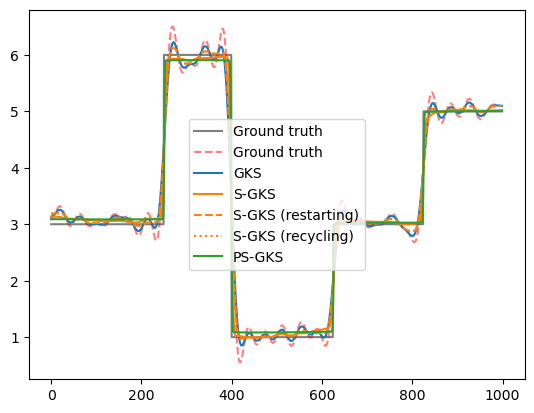

In [217]:
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.5)
plt.plot(A.T @ b, label="Ground truth", color="red", alpha=0.5, ls="--")
plt.plot(vdata["x"], label="GKS", color="C0")
plt.plot(data["x"], label="S-GKS", color="C1")
plt.plot(resdata["x"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(resdata["x"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["x"], label="PS-GKS", color="C2")
plt.legend()
plt.show()

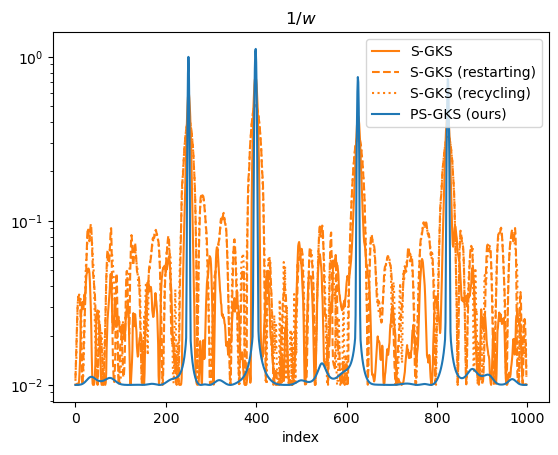

In [213]:
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
plt.semilogy(1.0/data['w'], label="S-GKS", color="C1")
plt.semilogy(1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(1.0/pdata['w'], label="PS-GKS (ours)")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

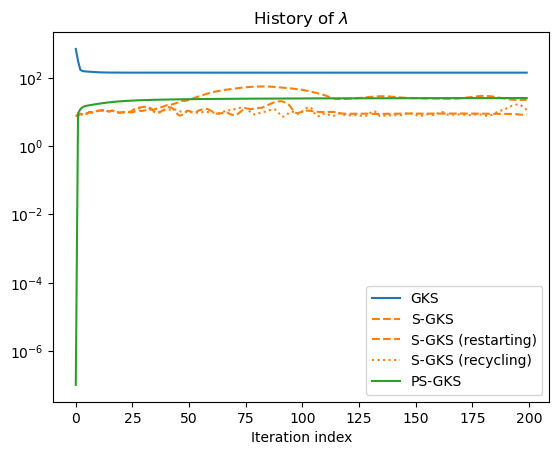

In [214]:
plt.semilogy(vdata["lambda_history"], label="GKS", color="C0")
plt.semilogy(data["lambda_history"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C2")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

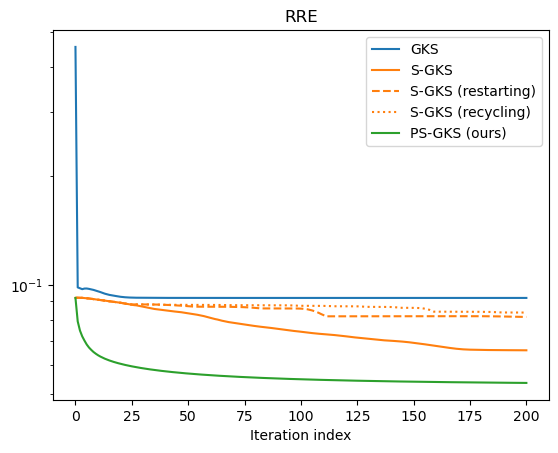

In [192]:
plt.semilogy(vdata["rre_history"], label="GKS", color="C0")
plt.semilogy(data["rre_history"], label="S-GKS", color="C1")
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C2")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

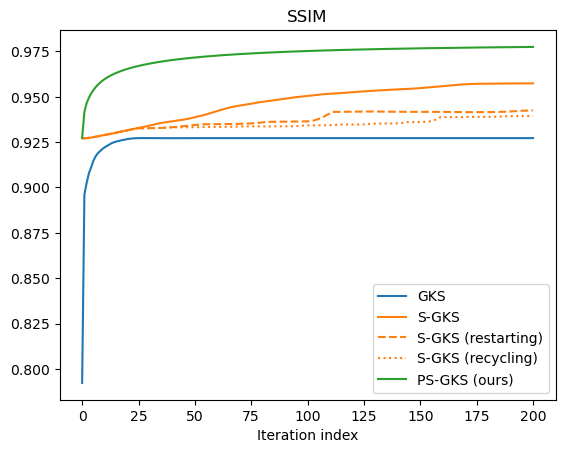

In [193]:
plt.plot(vdata["ssim_history"], label="GKS", color="C0")
plt.plot(data["ssim_history"], label="S-GKS", color="C1")
plt.plot(resdata["ssim_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.plot(recdata["ssim_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.plot(pdata["ssim_history"], label="PS-GKS (ours)", color="C2")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

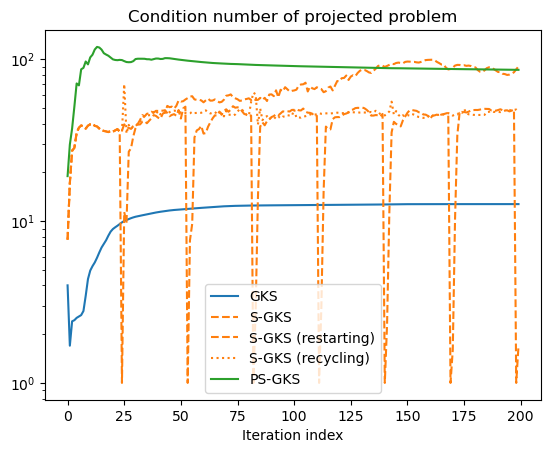

In [60]:
plt.semilogy(vdata["cond_ests"], label="GKS", color="C0")
plt.semilogy(data["cond_ests"], label="S-GKS", ls="--", alpha=1.0, color="C1")
plt.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
plt.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
plt.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C2")
plt.title("Condition number of projected problem")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Plots in the paper

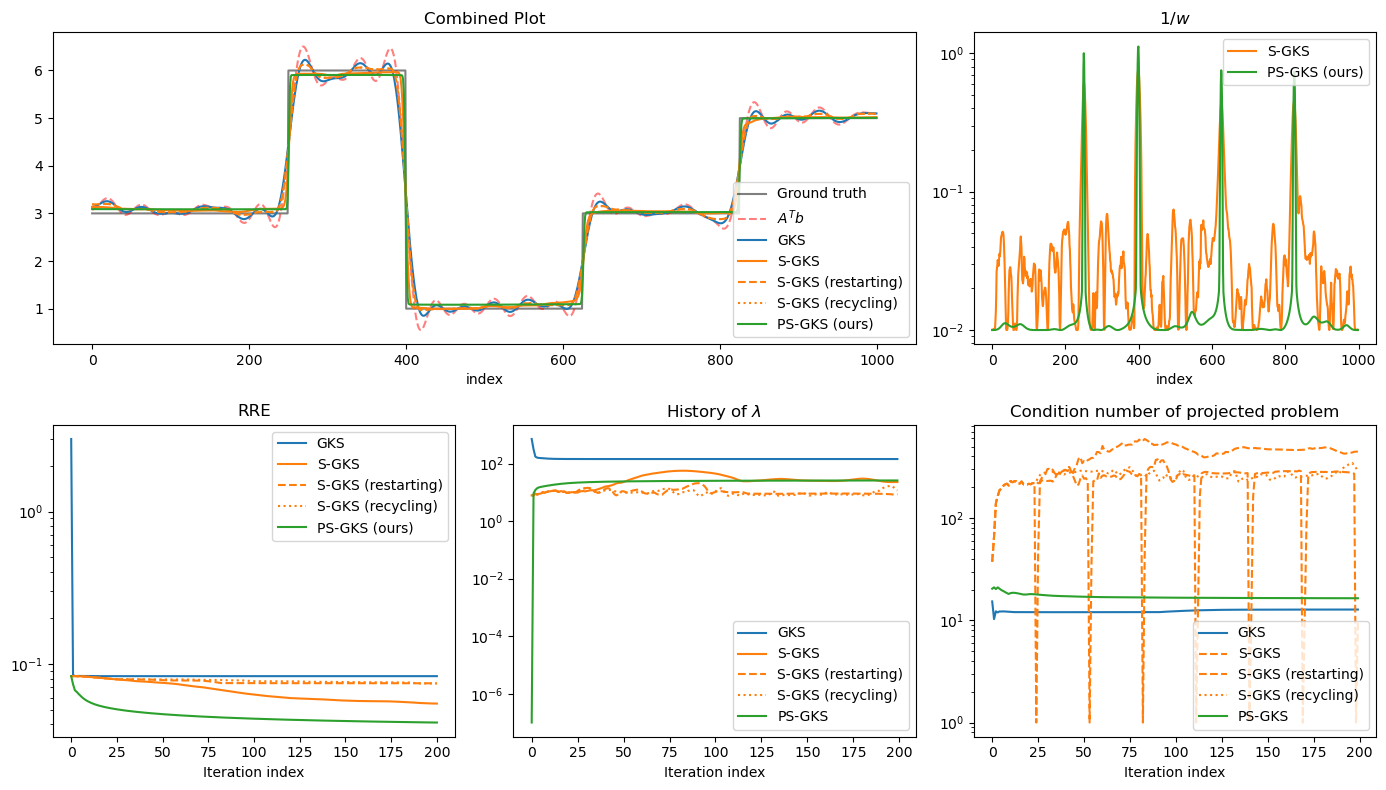

In [218]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(14, 8))
gs = gridspec.GridSpec(2, 3, figure=fig)

# Combine the first two subplots at positions (0,0) and (0,1)
ax1 = fig.add_subplot(gs[0, :2])
ax1.plot(ground_truth, label="Ground truth", color="k", alpha=0.5)
ax1.plot(A.T @ b, label="$A^T b$", color="red", alpha=0.5, ls="--")
ax1.plot(vdata["x"], label="GKS", color="C0")
ax1.plot(data["x"], label="S-GKS", color="C1")
ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C1", ls="--")
ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C1", ls=":")
ax1.plot(pdata["x"], label="PS-GKS (ours)", color="C2")
ax1.legend(loc="lower right")
ax1.set_xlabel("index")
ax1.set_title('Combined Plot')


# Add the remaining subplots
ax2 = fig.add_subplot(gs[0, 2])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax2.semilogy(1.0/data['w'], label="S-GKS", color="C1")
#ax2.semilogy(1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--")
#ax2.semilogy(1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax2.semilogy(1.0/pdata['w'], label="PS-GKS (ours)", color="C2")
ax2.set_title("$1/w$")
ax2.set_xlabel("index")
ax2.legend()

ax3 = fig.add_subplot(gs[1, 0])
ax3.set_title('Subplot (1,0)')
ax3.semilogy(vdata["rre_history"], label="GKS", color="C0")
ax3.semilogy(data["rre_history"], label="S-GKS", color="C1")
ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax3.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C2")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
ax3.set_title("RRE")
ax3.set_xlabel("Iteration index")
ax3.legend()


ax4 = fig.add_subplot(gs[1, 1])
ax4.set_title('Subplot (1,1)')
ax4.semilogy(vdata["lambda_history"], label="GKS", color="C0")
ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C1")
ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C2")
ax4.set_title("History of $\\lambda$")
ax4.set_xlabel("Iteration index")
ax4.legend()

ax5 = fig.add_subplot(gs[1, 2])
ax5.semilogy(vdata["cond_ests"], label="GKS", color="C0")
ax5.semilogy(data["cond_ests"], label="S-GKS", ls="--", alpha=1.0, color="C1")
ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C2")
ax5.set_title("Condition number of projected problem")
ax5.set_xlabel("Iteration index")
ax5.legend(loc="lower right")


# Adjust layout
fig.tight_layout()
# fig.savefig("1d_cosine_example.png", dpi=250, bbox_inches=None)
# fig.savefig("1d_cosine_example.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


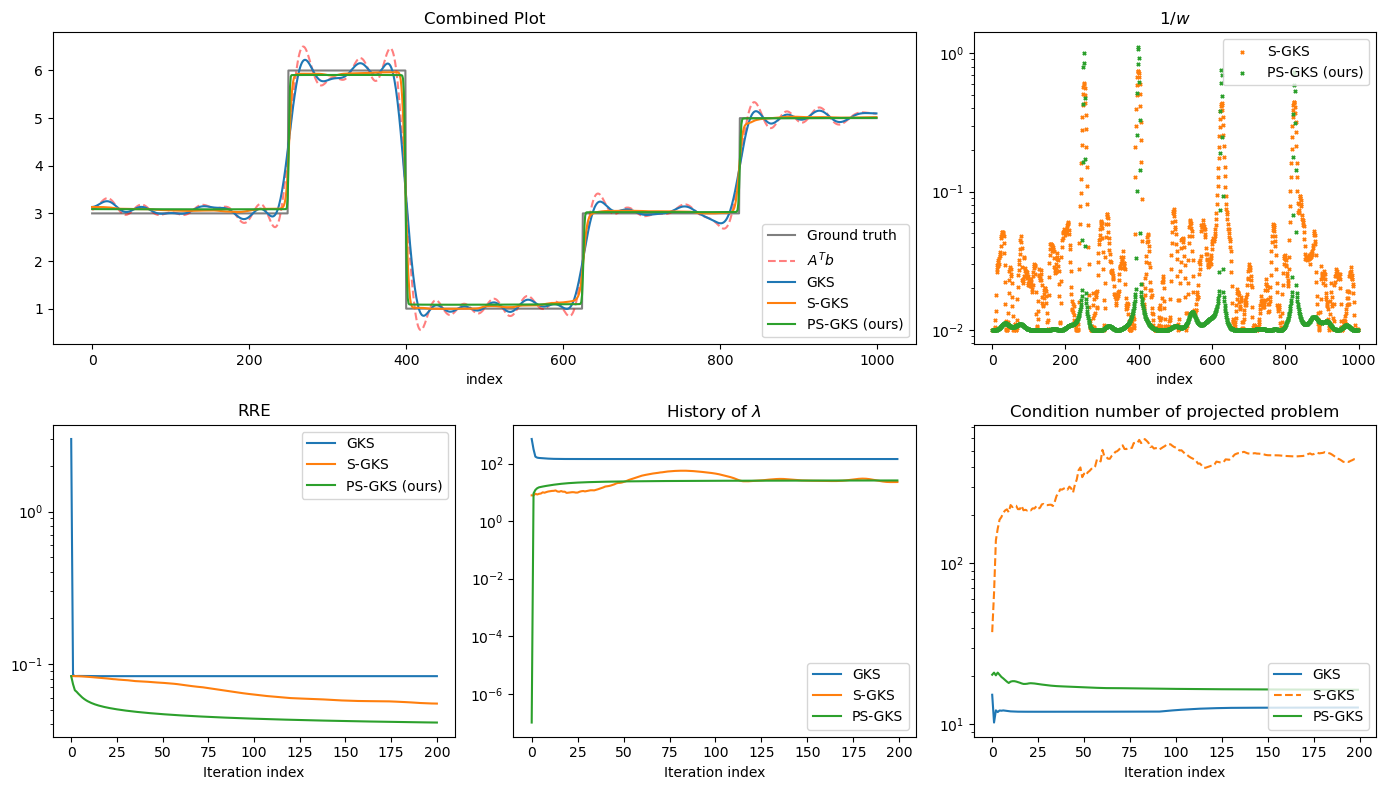

In [228]:
# Create a figure with a 2x3 grid
fig = plt.figure(figsize=(14, 8))
gs = gridspec.GridSpec(2, 3, figure=fig)

# Combine the first two subplots at positions (0,0) and (0,1)
ax1 = fig.add_subplot(gs[0, :2])
ax1.plot(ground_truth, label="Ground truth", color="k", alpha=0.5)
ax1.plot(A.T @ b, label="$A^T b$", color="red", alpha=0.5, ls="--")
ax1.plot(vdata["x"], label="GKS", color="C0")
ax1.plot(data["x"], label="S-GKS", color="C1")
#ax1.plot(resdata["x"], label="S-GKS (restarting)", color="C1", ls="--")
#ax1.plot(resdata["x"], label="S-GKS (recycling)", color="C1", ls=":")
ax1.plot(pdata["x"], label="PS-GKS (ours)", color="C2")
ax1.legend(loc="lower right")
ax1.set_xlabel("index")
ax1.set_title('Combined Plot')


# Add the remaining subplots
ax2 = fig.add_subplot(gs[0, 2])
#plt.semilogy(1.0/vdata['w'], label="GKS", color="C0")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/data['w'], label="S-GKS", color="C1", marker="x", s=5)
#ax2.semilogy(1.0/resdata['w'], label="S-GKS (restarting)", color="C1", ls="--")
#ax2.semilogy(1.0/recdata['w'], label="S-GKS (recycling)", color="C1", ls=":")
ax2.scatter([i for i in range(len(data["w"]))], 1.0/pdata['w'], label="PS-GKS (ours)", color="C2", marker="x", s=5)
ax2.set_yscale("log")
ax2.set_title("$1/w$")
ax2.set_xlabel("index")
ax2.legend()

ax3 = fig.add_subplot(gs[1, 0])
ax3.set_title('Subplot (1,0)')
ax3.semilogy(vdata["rre_history"], label="GKS", color="C0")
ax3.semilogy(data["rre_history"], label="S-GKS", color="C1")
#ax3.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
#ax3.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax3.semilogy(pdata["rre_history"], label="PS-GKS (ours)", color="C2")
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
ax3.set_title("RRE")
ax3.set_xlabel("Iteration index")
ax3.legend()


ax4 = fig.add_subplot(gs[1, 1])
ax4.set_title('Subplot (1,1)')
ax4.semilogy(vdata["lambda_history"], label="GKS", color="C0")
ax4.semilogy(data["lambda_history"], label="S-GKS", alpha=1.0, color="C1")
#ax4.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
#ax4.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
ax4.semilogy(pdata["lambda_history"], label="PS-GKS", alpha=1.0, color="C2")
ax4.set_title("History of $\\lambda$")
ax4.set_xlabel("Iteration index")
ax4.legend()

ax5 = fig.add_subplot(gs[1, 2])
ax5.semilogy(vdata["cond_ests"], label="GKS", color="C0")
ax5.semilogy(data["cond_ests"], label="S-GKS", ls="--", alpha=1.0, color="C1")
#ax5.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", ls="--", alpha=1.0, color="C1")
#ax5.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", ls=":", alpha=1.0, color="C1")
ax5.semilogy(pdata["cond_ests"], label="PS-GKS", alpha=1.0, color="C2")
ax5.set_title("Condition number of projected problem")
ax5.set_xlabel("Iteration index")
ax5.legend(loc="lower right")


# Adjust layout
fig.tight_layout()
fig.savefig("1d_cosine_example.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example.eps", format="eps", dpi=250, bbox_inches=None)
plt.show()


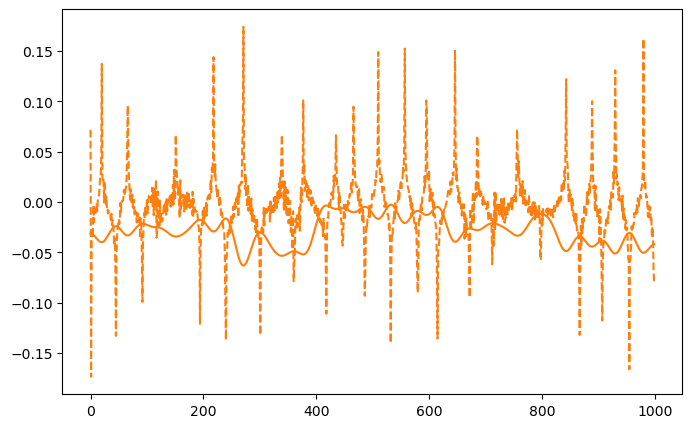

In [63]:
plt.figure(figsize=(8,5))

kk = 0
plt.plot(data["V"][:,kk], label=f"S-GKS, basis vector {kk}", color="C1")
kk = 5
plt.plot(data["V"][:,kk], label=f"S-GKS, basis vector {kk}", color="C1", ls="--")


plt.show()


In [67]:
# fig, axs = plt.subplots(3,2, figsize=(13,5))

# kk = 0
# axs[0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C1")
# kk = 4
# axs[0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C1", ls="--")
# kk = 9
# axs[0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C1", ls=":")
# axs[0].set_title("S-GKS")

# axs[0].legend()


# kk = 0
# axs[1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C2")
# kk = 4
# axs[1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C2", ls="--")
# kk = 9
# axs[1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C2", ls=":")

# axs[1].legend()
# axs[1].set_title("PS-GKS (ours)")


# # Adjust layout
# fig.tight_layout()
# fig.savefig("1d_cosine_example_basis_vectors.png", dpi=250, bbox_inches=None)
# fig.savefig("1d_cosine_example_basis_vectors.eps", format="eps", dpi=250, bbox_inches=None)
# plt.show()

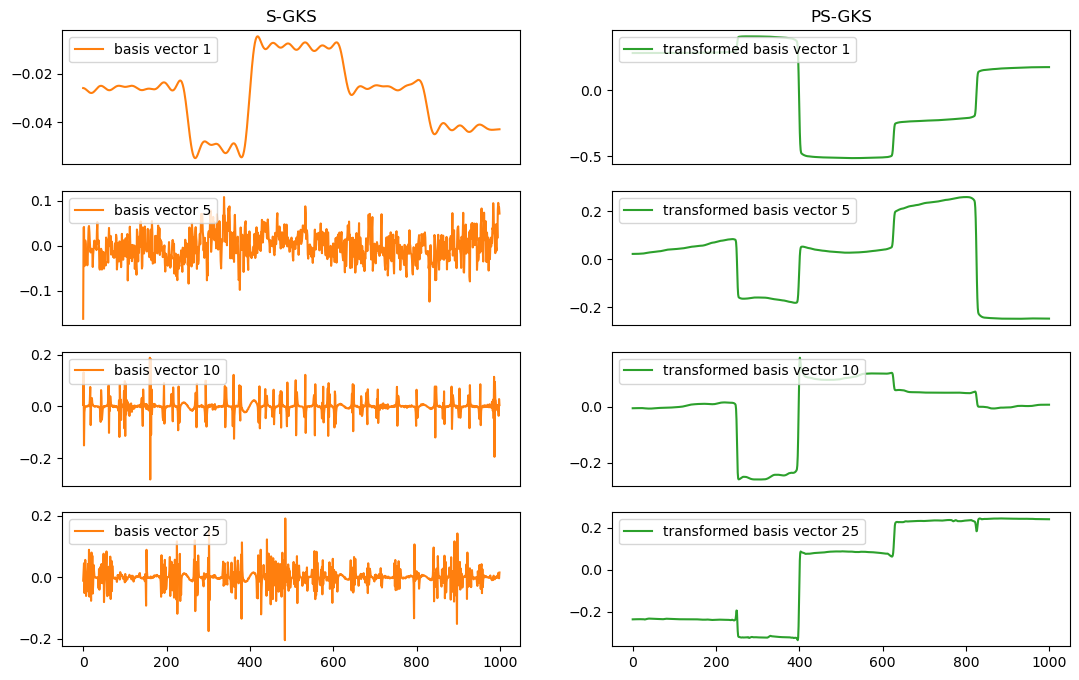

In [229]:
fig, axs = plt.subplots(4,2, figsize=(13,8))

loc = "upper left"

kk = 0
axs[0,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C1")
axs[0,0].legend(loc=loc)
axs[0,0].set_xticks([])
axs[0,0].set_title("S-GKS")

kk = 4
axs[1,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C1")
axs[1,0].legend(loc=loc)
axs[1,0].set_xticks([])

kk = 9
axs[2,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C1")
axs[2,0].legend(loc=loc)
axs[2,0].set_xticks([])

kk = 24
axs[3,0].plot(data["V"][:,kk], label=f"basis vector {kk+1}", color="C1")
axs[3,0].legend(loc=loc)




kk = 0
axs[0,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C2")
axs[0,1].legend(loc=loc)
axs[0,1].set_xticks([])
axs[0,1].set_title("PS-GKS")

kk = 4
axs[1,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C2")
axs[1,1].legend(loc=loc)
axs[1,1].set_xticks([])

kk = 9
axs[2,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C2")
axs[2,1].legend(loc=loc)
axs[2,1].set_xticks([])

kk = 24
axs[3,1].plot(pdata["Lopinv"] @ pdata["V"][:,kk], label=f"transformed basis vector {kk+1}", color="C2")
axs[3,1].legend(loc=loc)

fig.savefig("1d_cosine_example_basis_vectors.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_example_basis_vectors.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

# L2 GKS

In [14]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

In [15]:
# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)

err_norm_sq = len(b) # in expectation

# Build solver
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b)

In [16]:
method = "dp"
vpdata = gks_solver.solve_with_priorconditioning(n_iter=100, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params={}, 
                                                 regparam_kwargs={"eta":1.01})

vdata = gks_solver.solve(n_iter=100, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)


1e-07


/home/jlindbloom/Github/IRLS_prec_GSBL/tests/1d_cosine/../../msolver.py:662: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


29.37311796347164
39.13404065587531
41.177732121567
41.97943207734817
42.14978036754988
42.19826446337829
42.20455802598726
42.205294778123
42.20537639786833
42.205386672600255
42.20538777482808
42.2053878282381
42.20538783144166
42.205387831569546
42.20538783157511
42.20538783157513
42.20538783157523
42.20538783157528
42.205387831575194
42.20538783157522
42.2053878315752
42.20538783157518
42.20538783157526
42.20538783157523
42.20538783157524
42.2053878315753
42.20538783157534
42.20538783157535
42.205387831575166
42.20538783157517
42.205387831575266
42.20538783157521
42.20538783157512
42.20538783157514
42.2053878315752
42.20538783157522
42.205387831575216
42.20538783157521
42.20538783157519
42.2053878315752
42.205387831575166
42.205387831575145
42.20538783157523
42.20538783157517
42.20538783157524
42.20538783157525
42.20538783157524
42.20538783157524
42.20538783157522
42.20538783157522
42.20538783157518
42.20538783157523
42.20538783157524
42.205387831575216
42.205387831575266
42.205387

41.42654904351062


/home/jlindbloom/Github/IRLS_prec_GSBL/tests/1d_cosine/../../msolver.py:396: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


46.73357399281695
58.049122682427324
67.22046246366237
72.11489665980756
74.78235628893248
76.18153202714056
77.19522604185087
78.06959717999142
78.94940052345962
79.82723977327085
80.65730111879728
81.2441899772504
81.35623812880151
80.82254326295599
79.54941532707379
77.53788131242052
74.74883738842232
70.96661252904158
66.67130150867705
62.990710615993024
59.92400815135788
57.749989393767784
55.91878441209861
54.1710921829452
52.59094819400645
51.567106380409676
50.70206992767772
49.875454710696296
49.18997231139442
48.47822116163381
47.8423850099834
47.23607306853693
46.60811509599445
45.990272271265994
45.3533829123144
44.8045259331109
44.32325127975976
43.94085675766336
43.64962906279351
43.41050747641793
43.228762388795516
43.082757013658714
42.961897006179306
42.86046810333388
42.76422736297953
42.687348594480646
42.636583739850465
42.602604632670676
42.57118314950072
42.54257980577378
42.521741997932196
42.50324963021195
42.48548548135685
42.46808939158823
42.44711929318595
42

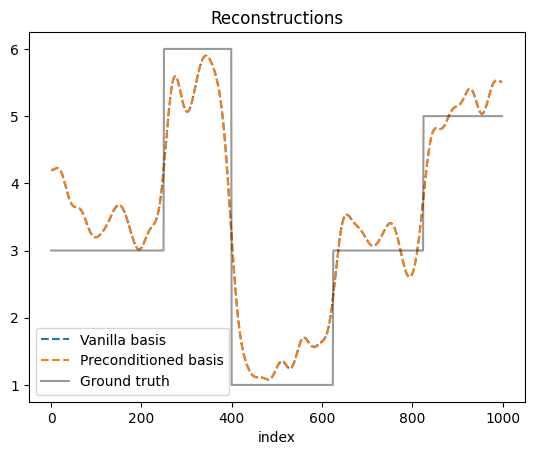

In [17]:
plt.plot(vdata['x'], label="Vanilla basis", ls="--")
plt.plot(vpdata['x'], label="Preconditioned basis", ls="--")
# plt.plot(rdata['x'], label="Restarted", ls="--")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

In [ ]:
plt.plot(vdata['x'], label="Vanilla basis", ls="--")

# Run PGKS (MM)

In [16]:
q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [17]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

In [18]:
# Set method
#method = "dp"
method = "optimal_ssim"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)

err_norm_sq = len(b) # in expectation

# Build solver
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [30]:
method = "dp"
pdata = mmgks_solver.solve_with_priorconditioning(n_iter=500, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params, 
                                                 regparam_kwargs={"eta":1.01})

data = mmgks_solver.solve(n_iter=500, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)



method = "optimal_ssim"
data_opt = mmgks_solver.solve(n_iter=500, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={}, min_dim=None, max_dim=None, xker=xker)

pdata_opt = mmgks_solver.solve_with_priorconditioning(n_iter=500, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={})


0.37997637204384044
2.0759855884752927
2.061022831625076
2.060388354695803
2.077742098779156
2.0866431922301825
2.0967931179972132
2.1044062439807165
2.11206881456443
2.1182579640915655
2.124308641025997
2.1289697422381466
2.133743325239997
2.1379666905128576
2.1414523228374973
2.145022614561865
2.14802058466138
2.1508004640488054
2.153541655553031
2.15581495828679
2.1581238426620604
2.1601692620484076
2.162117674522732
2.163925672338018
2.16561182555557
2.1672125264103363
2.1686875542914543
2.1700979782847853
2.1714058016730915
2.1726501588871607
2.17381505715834
2.1749209516509613
2.1759621384030017
2.176952818082282
2.177888139718455
2.1787801269736007
2.1796269652388083
2.180434365673649
2.181204966830433
2.1819404129481303
2.1826447511300735
2.1833180582256717
2.18396456107997
2.184584012158232
2.185179743325731
2.1857518563531153
2.1863026224817896
2.1868327070811655
2.1873436912273547
2.187836335603292
2.188311830859905
2.1887709628160166
2.189214591891169
2.189643536286014
2.19

0.60030777826629
5.2985296916609785
5.336277814287903
5.36234520363609
5.38883370187963
5.438786450225544
5.470505826271513
5.506085080088619
5.560868452724014
5.603380682239866
5.6305669545429495
5.699888630906657
5.739644441377578
5.789413234909468
5.838249106723936
5.881573187596772
5.981489554369226
6.007456260865529
6.069960742250384
6.136187862450014
6.1738293467667775
6.262751854937076
6.322523801152134
6.376014041832883
6.435028060559051
6.520564550060817
6.556456152218015
6.623336122242432
6.696811082089357
6.742265172761212
6.8097747858035
6.864759171291819
6.92637474534662
6.976206266289893
7.046450163968945
7.093830313649731
7.15663600092963
7.194578791587989
7.238033660697554
7.276544768870837
7.326302014202721
7.362049787053051
7.381862065770539
7.415217493590322
7.435321364214905
7.4599422073756365
7.468025488704787
7.4741353114867675
7.466016556693928
7.467554559626912
7.469076407665377
7.463223113156318
7.44345937651293
7.409234321765019
7.377554136429492
7.33539605090

1.0613562481699714
8.503329439889047
8.541490200979462
8.568766873229801
8.595108658328433
8.642889184338932
8.671394507080759
8.706901807320673
8.752248211067911
8.793068023766619
8.832032029917391
8.886391453802593
8.93147951536746
8.971899403286704
9.019769439734823
9.069576812852967
9.120883455842542
9.162798175009613
9.21225166077974
9.293964550286065
9.326215674556247
9.403486676866713
9.449973157044024
9.501044908510554
9.586883487163421
9.65905810825662
9.70473424286115
9.812600198149237
9.873351475473825
9.935981075958209
10.04688016706806
10.098883342953272
10.18882897994096
10.276208877304905
10.380651618762537
10.49766286683599
10.550609802182185
10.636780967649377
10.847480765088589
10.827679433256842
10.93148257734504
11.0828799128327
11.170782411854697
11.244290124437715
11.38608122161405
11.520526233679483
11.570479960200933
11.66901344834741
11.797645173496798
11.882624750147086
12.016857081445917
12.052990114104785
12.146494462898787
12.336554920568313
12.362853370432

0.5479849881258002
1.958264313972365
1.789474267407828
1.7285444714945177
1.6354066433047154
1.645134309037787
1.6724450892241327
1.6622572259017563
1.6320072679999134
1.6016558733614532
1.615179891427519
1.86217574763981
1.7666232505225867
1.7271370314726604
1.7164380603906246
1.718240992830709
1.7134702562389286
1.7109996437900274
1.715219094027469
1.7108849682817133
1.728303330536465
1.748997341204935
1.734306671021122
1.7313031484199337
1.7295397476960854
1.7301319521835379
1.729239779569651
1.7289440193846133
1.7280678159356513
1.7276160498573572
1.7283966565121498
1.7301625892052914
1.7290063870369579
1.7375891830550132
1.7381092045301831
1.7364005820031183
1.735766271242406
1.7365826163806812
1.736877575683137
1.7373940293506407
1.7377216307259482
1.7378954586240956
1.738321299946524
1.7388222621483767
1.7391789411033707
1.739583249100768
1.7404522134706946
1.7430469452415183
1.745387354700421
1.7456431617392032
1.7451547817283442
1.7459029320751596
1.746470162511194
1.747239013

In [20]:
# Recycling
method = "dp"
rdata = mmgks_solver.solve(n_iter=1005, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=5, max_dim=15, xker=None)

# # Restarting
# method = "dp"
# rdata = mmgks_solver.solve(n_iter=1005, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
#                                     regparam=method, x_true=ground_truth, weight_params=weight_params,
#                                     regparam_kwargs={"eta":1.01}, restart_dim=25, xker=pdata["xker"].copy())

0.60030777826629
5.2985296916609785
5.336277814287903
5.36234520363609
5.38883370187963
5.438786450225544
5.470505826271513
5.506085080088619
5.560868452724014
5.603380682239866
(15, 15)
(15, 15)
(30, 15)
2.265420013559729e-15
5.591358727105878
5.607899086196274
5.612472319850912
5.614308557709932
5.617501471668332
5.619186064868689
5.620939015518055
5.62299120965998
5.626143815447437
5.6312104252155075
(15, 15)
(15, 15)
(30, 15)
1.7302212302348852e-15
5.629886398534973
5.630849121851791
5.63156127723864
5.632803140134582
5.635885294192327
5.643755834932456
5.661419845680421
5.708193685607785
5.813268447086096
5.954589925848784
(15, 15)
(15, 15)
(30, 15)
2.212051480253358e-14
5.932203703976102
5.948101077651467
5.950958707897722
5.959262547750822
5.96599141497257
5.980778727645503
5.997377028696723
6.0258911597928755
6.051862429519519
6.07681053034626
(15, 15)
(15, 15)
(30, 15)
2.5466098086582417e-15
6.073641217667243
6.076582804518529
6.077619201737315
6.079879950742035
6.083302839733

In [2]:
plt.plot(ground_truth, color="k", label="Ground truth")
plt.plot(A.T @ b, color="red", ls="--", alpha=0.5, label="$A^T b$")
plt.title("Problem data")
plt.legend()
plt.show()

NameError: name 'plt' is not defined

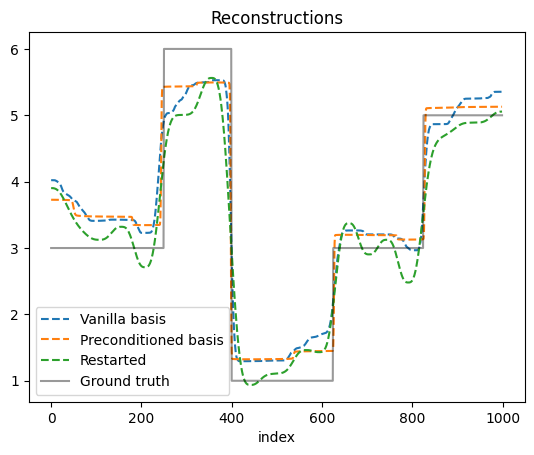

In [31]:
plt.plot(data['x'], label="Vanilla basis", ls="--")
plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
plt.plot(rdata['x'], label="Restarted", ls="--")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

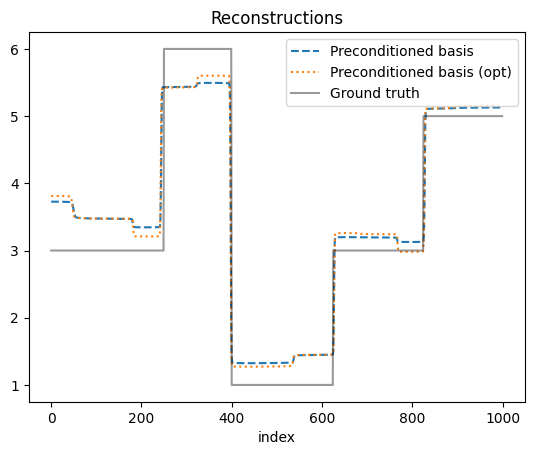

In [32]:
plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
plt.plot(pdata_opt['x'], label="Preconditioned basis (opt)", ls=":")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

In [1]:
plt.plot(data['x'], label="S-GKS (DP)")
plt.plot(data_opt['x'], label="S-GKS (optimal)", ls="--", alpha=0.7)
#plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
#plt.plot(pdata_opt['x'], label="Preconditioned basis (opt)", ls=":")
#plt.plot(rdata['x'], label="Restarted", ls="--")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

NameError: name 'plt' is not defined

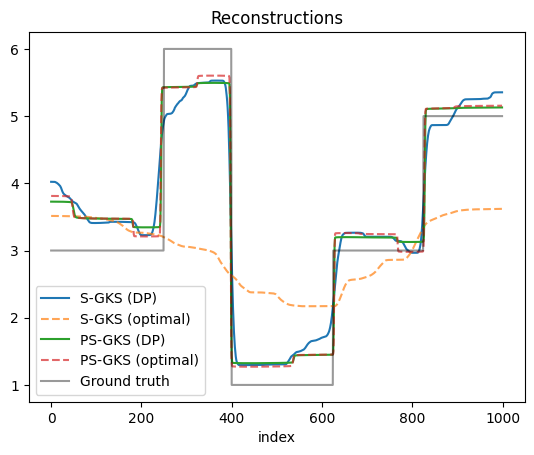

In [41]:
plt.plot(data['x'], label="S-GKS (DP)")
plt.plot(data_opt['x'], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.plot(pdata['x'], label="PS-GKS (DP)")
plt.plot(pdata_opt['x'], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.plot(rdata['x'], label="Restarted", ls="--")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

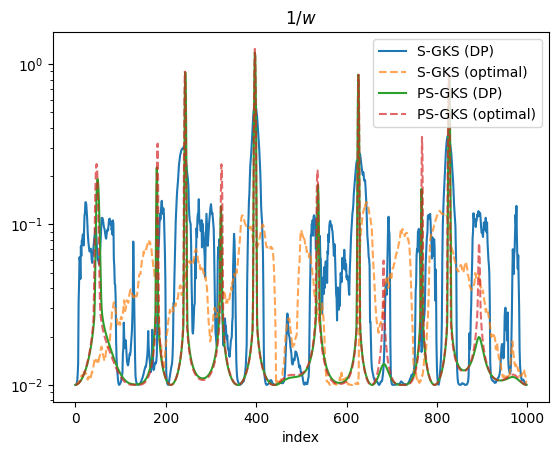

In [40]:
plt.semilogy(1.0/data['w'], label="S-GKS (DP)")
plt.semilogy(1.0/data_opt['w'], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(1.0/pdata['w'], label="PS-GKS (DP)")
plt.semilogy(1.0/pdata_opt['w'], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(1.0/rdata['w'], label="Restarted")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

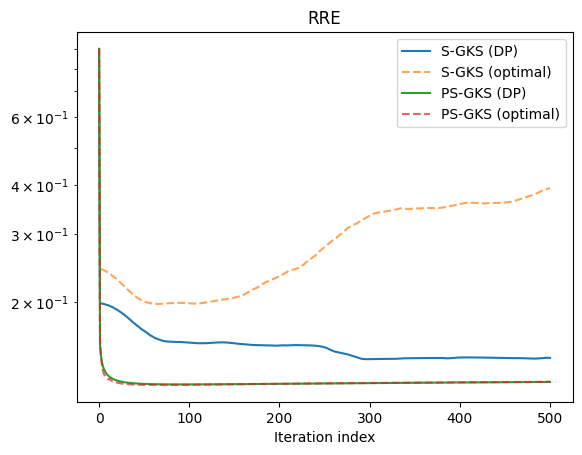

In [36]:
plt.semilogy(data["rre_history"], label="S-GKS (DP)")
plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["rre_history"], label="PS-GKS (DP)")
plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

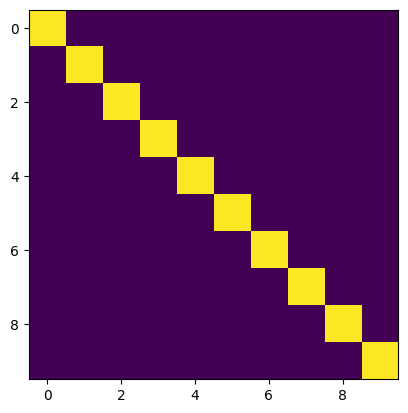

In [28]:
plt.imshow(rdata["V"].T @ rdata["V"])
plt.show()

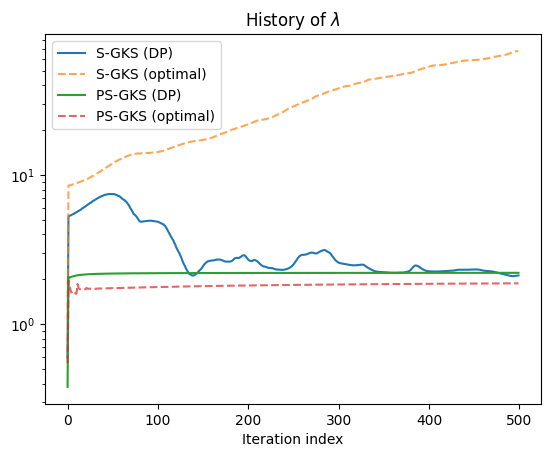

In [37]:
plt.semilogy(data["lambda_history"], label="S-GKS (DP)")
plt.semilogy(data_opt["lambda_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["lambda_history"], label="PS-GKS (DP)")
plt.semilogy(pdata_opt["lambda_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["lambda_history"], label="Restarted")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [1]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.semilogy(rdata["lambda_history"], label="Restarted")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

NameError: name 'plt' is not defined

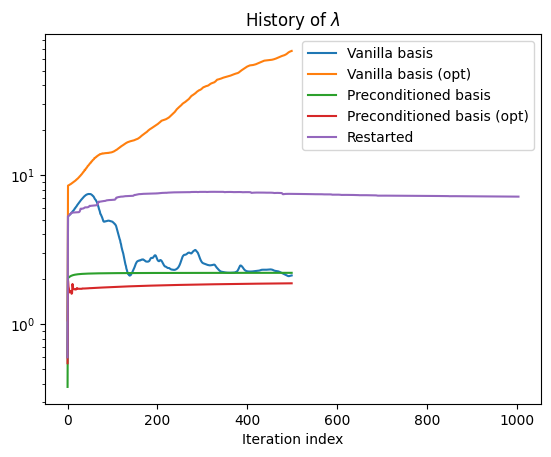

In [38]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(data_opt["lambda_history"], label="Vanilla basis (opt)")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.semilogy(pdata_opt["lambda_history"], label="Preconditioned basis (opt)")
plt.semilogy(rdata["lambda_history"], label="Restarted")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

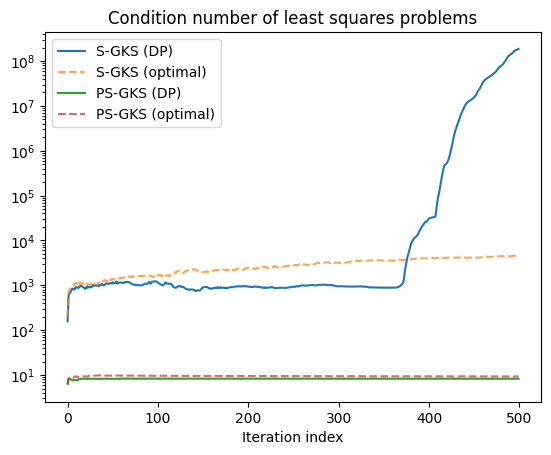

In [39]:
plt.semilogy(data["cond_ests"], label="S-GKS (DP)")
plt.semilogy(data_opt["cond_ests"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["cond_ests"], label="PS-GKS (DP)")
plt.semilogy(pdata_opt["cond_ests"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

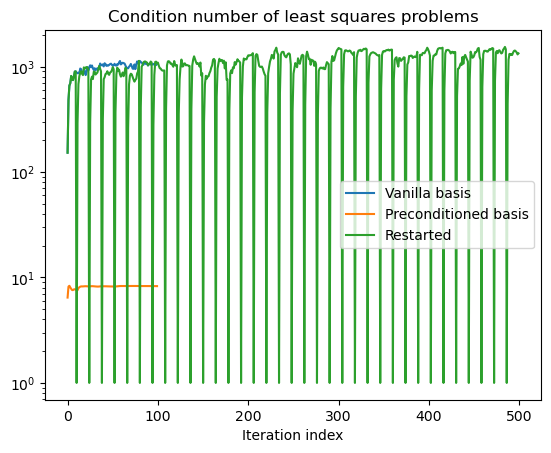

In [34]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.semilogy(rdata["cond_ests"], label="Restarted")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

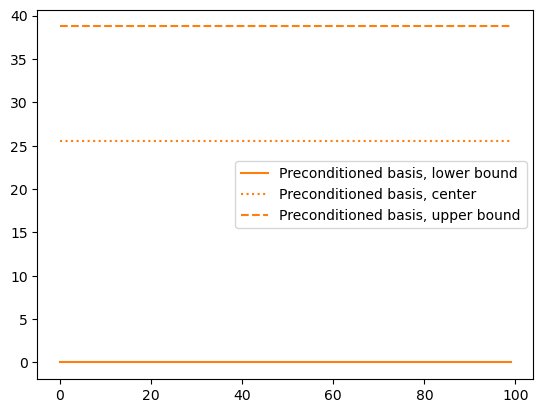

In [35]:
plt.plot(data["dp_ineq_lhs"], label="Preconditioned basis, lower bound", color="C1")
plt.plot(data["dp_ineq_chs"], label="Preconditioned basis, center", color="C1", ls=":")
plt.plot(data["dp_ineq_rhs"], label="Preconditioned basis, upper bound", color="C1", ls="--")
plt.legend()
plt.show()

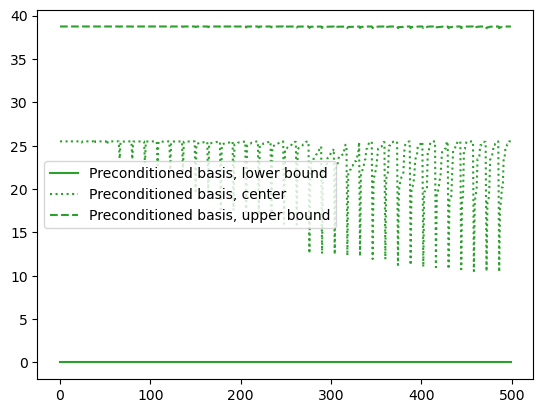

In [36]:
plt.plot(rdata["dp_ineq_lhs"], label="Preconditioned basis, lower bound", color="C2")
plt.plot(rdata["dp_ineq_chs"], label="Preconditioned basis, center", color="C2", ls=":")
plt.plot(rdata["dp_ineq_rhs"], label="Preconditioned basis, upper bound", color="C2", ls="--")
plt.legend()
plt.show()

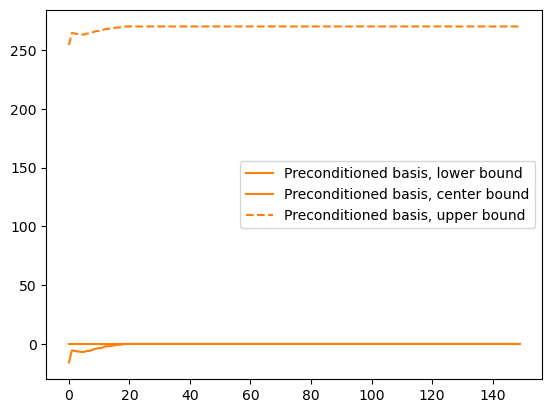

In [24]:
plt.plot(pdata["dp_ineq_lhs"], label="Preconditioned basis, lower bound", color="C1")
plt.plot(pdata["dp_ineq_chs"], label="Preconditioned basis, center bound", color="C1")
plt.plot(pdata["dp_ineq_rhs"], label="Preconditioned basis, upper bound", color="C1", ls="--")
plt.legend()
plt.show()

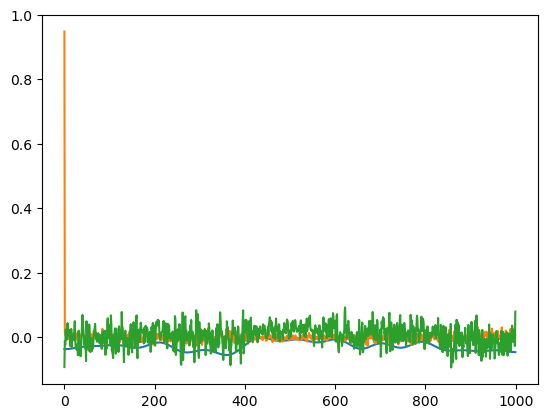

In [23]:
plt.plot(data["V"][:,0])
plt.plot(data["V"][:,1])
plt.plot(data["V"][:,2])
plt.show()

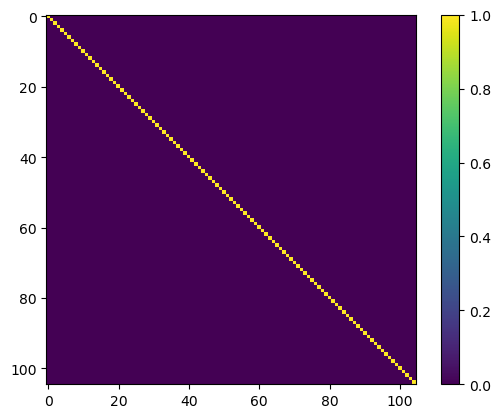

In [21]:
plt.imshow(data["V"].T @ data["V"])
plt.colorbar()
plt.show()

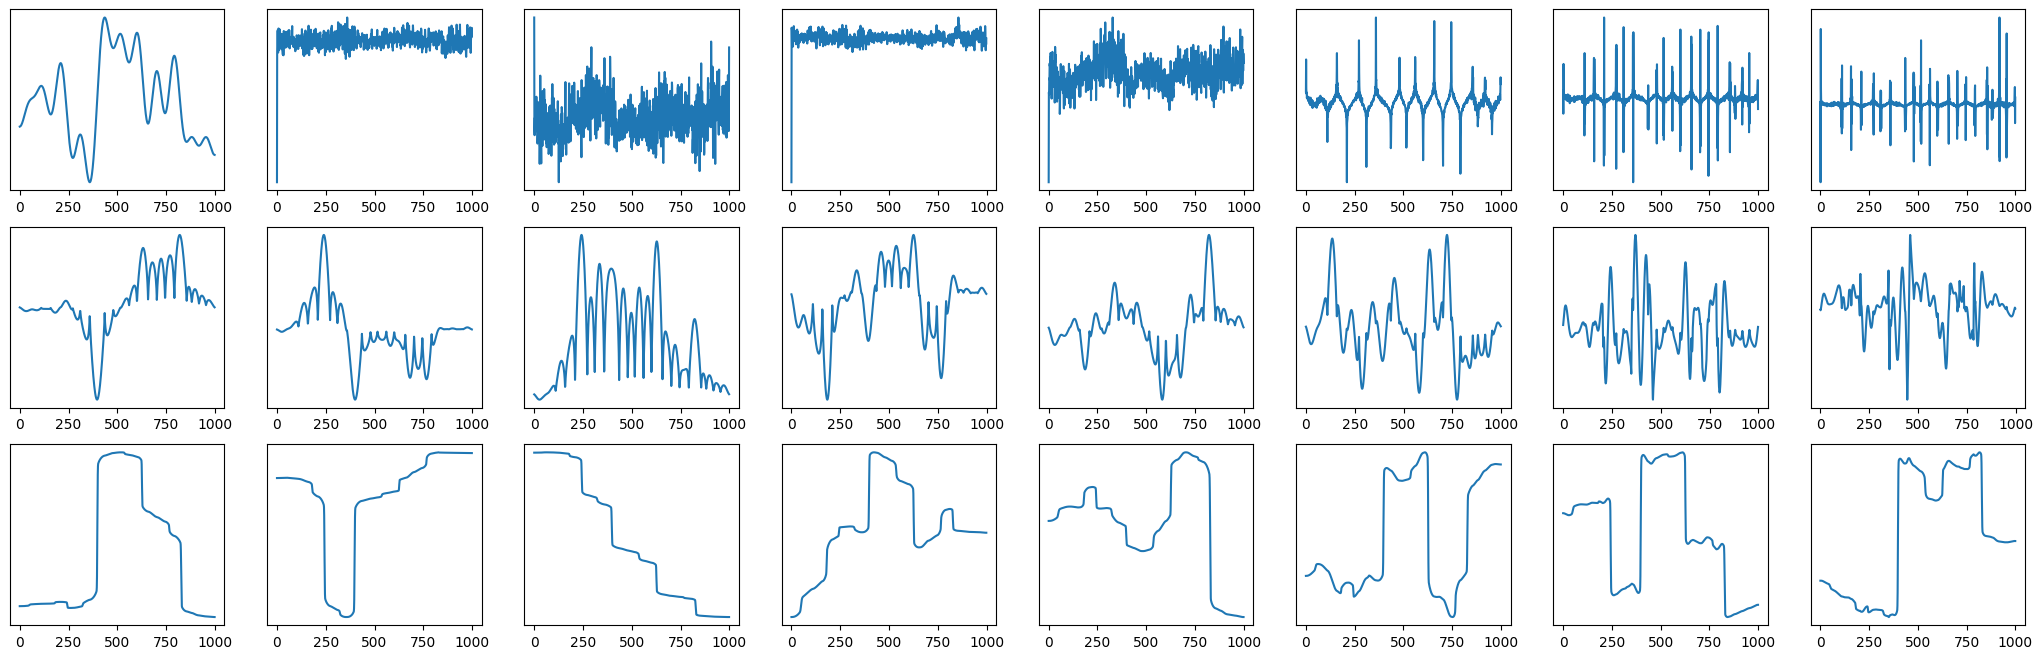

In [56]:
fig, axs = plt.subplots(3,8,figsize=(26,8))


for j in range(8):

    axs[0,j].plot(data["V"][:,j]) 
    axs[0,j].set_yticks([])

# Preconditioned


for j in range(8):

    axs[1,j].plot(pdata["V"][:,j])
    axs[1,j].set_yticks([])



for j in range(8):

    axs[2,j].plot((pdata["Lopinv"] @ pdata["V"][:,j]) )
    axs[2,j].set_yticks([])


plt.show()

In [62]:
rdata["V"].shape

(1000, 36)

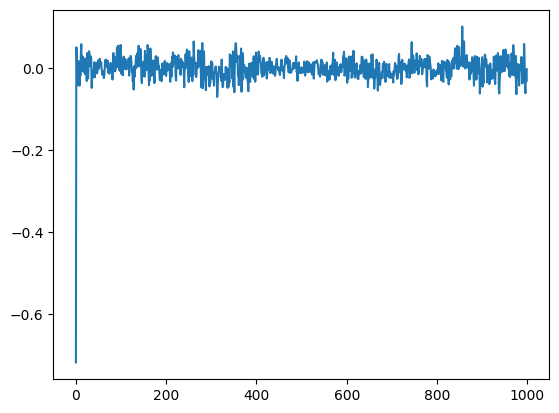

In [42]:
plt.plot(data["V"][:,3])
plt.show()

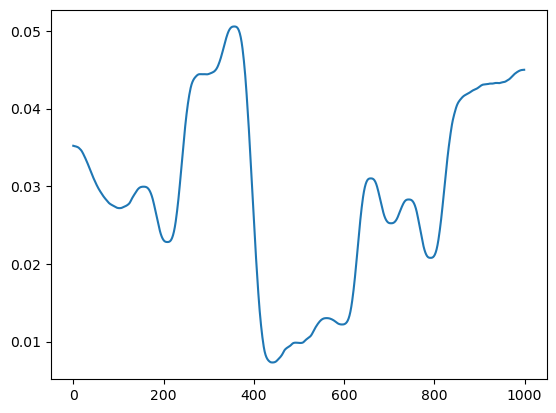

In [33]:
plt.plot(data["V"][:,4])
plt.show()

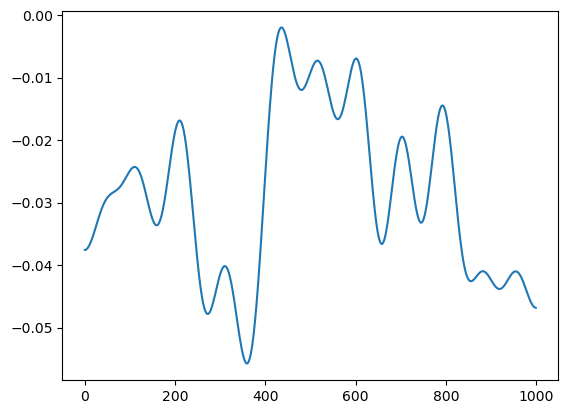

In [27]:
plt.plot(rdata["V"][:,0])
plt.show()

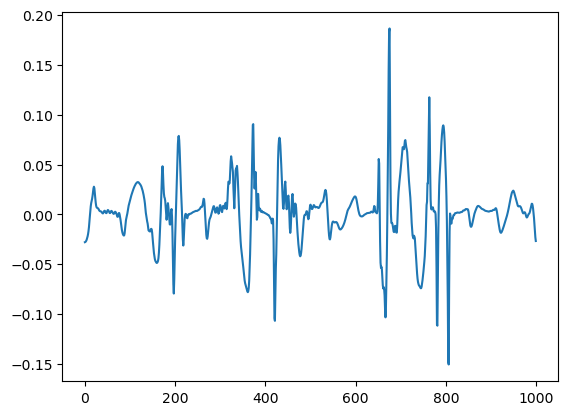

In [67]:
plt.plot(rdata["V"][:,1])
plt.show()

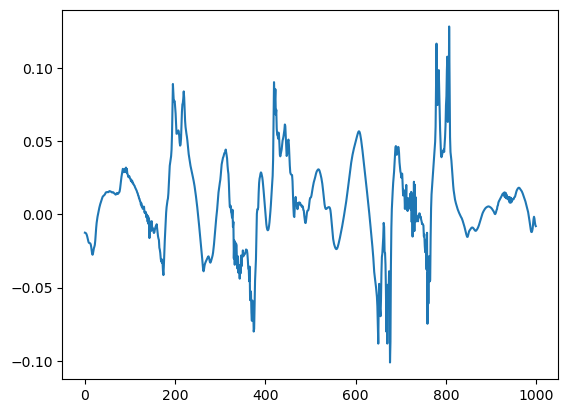

In [65]:
plt.plot(rdata["V"][:,5])
plt.show()

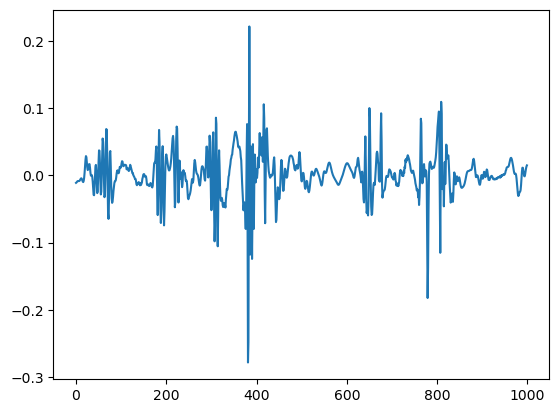

In [66]:
plt.plot(rdata["V"][:,6])
plt.show()

# Run PGKS (IAS)

In [50]:
n_iters = 200

# weight_params = {
#     "hyperpr_r": 1.0,
#     "hyperpr_beta": 1.5 + 1e-9,
# }

weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

In [51]:
# Set method
method = "dp3"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)

err_norm_sq = len(b) # in expectation

# Build solver
iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


# # Run the solver
# ias_data = ias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)


In [60]:
data = iasgks_solver.solve(n_iter=60, init_dim=5, x0=ground_truth, lambdah0=1e0, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = iasgks_solver.solve_with_priorconditioning(n_iter=100, init_dim=5, x0=ground_truth, lambdah0=1e0, lambdah_max=1e7,
                                                 regparam="dp", x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

181.35863416379647
238.17001826575205
297.44539169630974
319.8527295620565
286.86409451915074
167.9848736754269
98.19872343581171
77.53893751742206
69.43868765296308
65.73802182907957
63.63477445168017
62.16839745776087
61.24511360737193
60.551218214279956
60.000893195101234
59.56066163925986
59.20959001958904
58.9359877351567
58.71891739982333
58.51790583282869
58.336091296681424
58.16303783090561
57.97694570566485
57.79575088778645
57.610466786872074
57.437521123520526
57.290239797928194
57.171704685487875
57.08018846761589
56.99497342131969
56.92311921961992
56.859773317350005
56.79707598665938
56.73761611720552
56.68326493179907
56.638695046089786
56.602368861013666
56.57182369299977
56.54742966702878
56.52757724994552
56.51017984264618
56.49495324813207
56.48070179006456
56.465853629496756
56.452897331266854
56.442076101838495
56.43259599594699
56.42324016911323
56.414602423442524
56.40727847343826
56.40099809101768
56.395477875062625
56.39069190085081
56.385938513547956
56.381997

1e-06


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/msolver.py:505: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-06
1e-06
35.46996233772145
50.02698957428964
57.73927112542076
61.62178890808102
65.64307461352438
77.13636085996923
80.15011938679
88.47287891908394
91.78427265541247
92.35138628687626
92.41297411105603
92.42195004798957
92.43104043157558
92.4315206798125
92.43191781678364
92.43205539523682
92.43212033544233
92.4321101608002
92.43210799107325
92.43210755035018
92.43210744471628
92.4321073958643
92.43210737024452
92.43210736192688
92.43210736448702
92.43210736569927
92.43210736585779
92.43210736589174
92.43210736589994
92.43210736590243
92.43210736590268
92.4321073659029
92.43210736590284
92.43210736590295
92.43210736590297
92.43210736590267
92.43210736590277
92.4321073659029
92.43210736590282
92.43210736590275
92.4321073659029
92.4321073659029
92.43210736590297
92.43210736590291
92.43210736590291
92.43210736590288
92.43210736590288
92.4321073659029
92.43210736590292
92.43210736590304
92.43210736590291
92.43210736590292
92.43210736590294
92.4321073659028
92.43210736590301
92.4321073

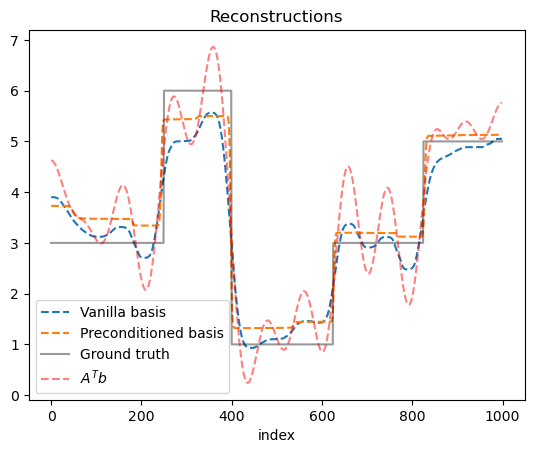

In [23]:
plt.plot(data['x'], label="Vanilla basis", ls="--")
plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.plot(A.T @ b, color="red", ls="--", alpha=0.5, label="$A^T b$")
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

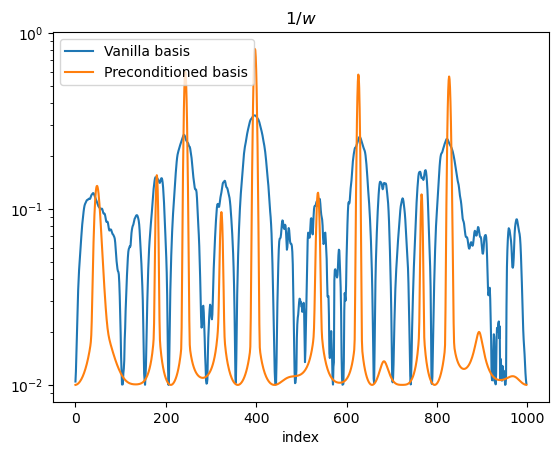

In [24]:
plt.semilogy(1.0/data['w'], label="Vanilla basis")
plt.semilogy(1.0/pdata['w'], label="Preconditioned basis")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

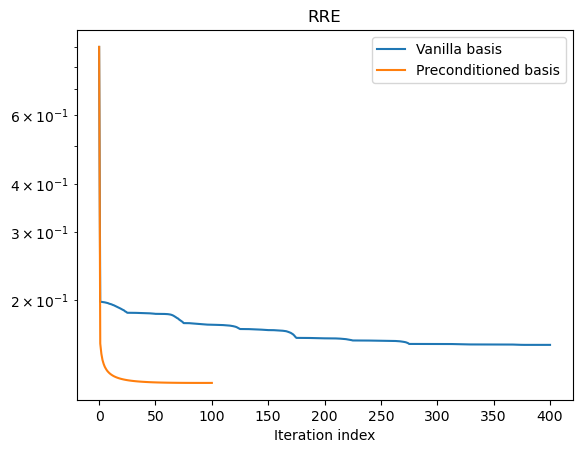

In [25]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

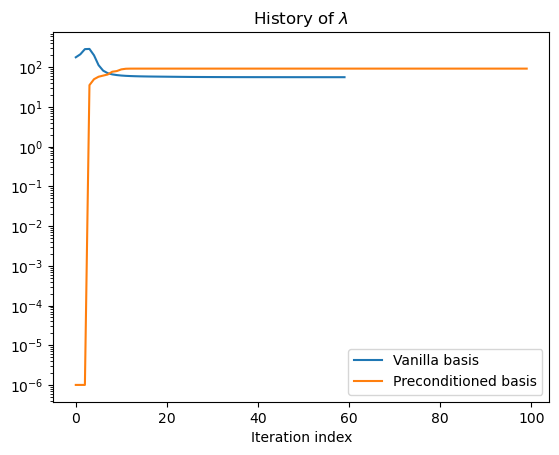

In [56]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

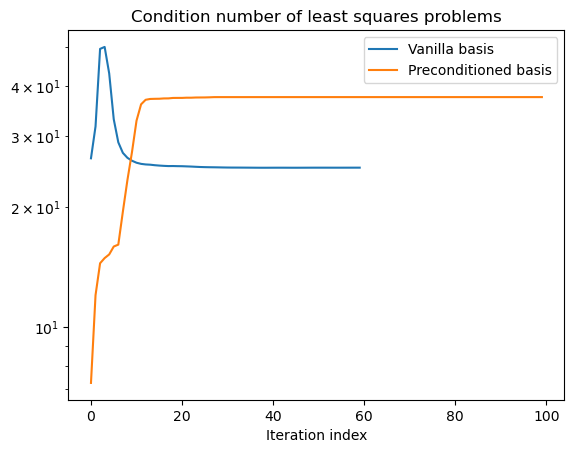

In [57]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# VGKS

In [101]:
q = 1.0
epsilon = 1e-3
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [102]:
vmmgks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

vdata = vmmgks_solver.solve(n_iter=100, init_dim=5, x0=ground_truth, lambdah0=1e0, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

# pdata = iasgks_solver.solve_with_priorconditioning(n_iter=100, init_dim=5, x0=ground_truth, lambdah0=1e0, lambdah_max=1e7,
#                                                  regparam="dp", x_true=ground_truth, weight_params=weight_params,
#                                                  regparam_kwargs={"eta":1.01})

95.63638774098084
99.57438470670274
109.88684373525557
117.88869085619005
117.27375191997814
105.27723067081475
91.20605752949967
82.56243960969933
77.22632752428238
73.78626577195791
71.52310959708399
70.00189550881765
68.77421921247976
67.8474818022305
67.12100093237073
66.52161661718682
66.06650132291188
65.65708217396427
65.21977227736761
64.72575767929675
64.20444407401193
63.648016913684266
63.025030078374755
62.39919398449769
61.76891307946625
61.1062013520709
60.414861441180086
59.758200144930726
59.20591959687392
58.710707922196725
58.27403110414954
57.87154097596936
57.49561183424449
57.18299382682447
56.89991952318775
56.621910489062266
56.38275035816994
56.16546499197656
55.9510905350146
55.71695508159592
55.504010345137644
55.303834485338804
55.166514036621166
55.03507035240116
54.89889571922067
54.78711020390276
54.67489134638194
54.57253921533729
54.48525259521718
54.40809847266594
54.346338469859155
54.28646441241893
54.22524539555525
54.161434257158945
54.1002589587693

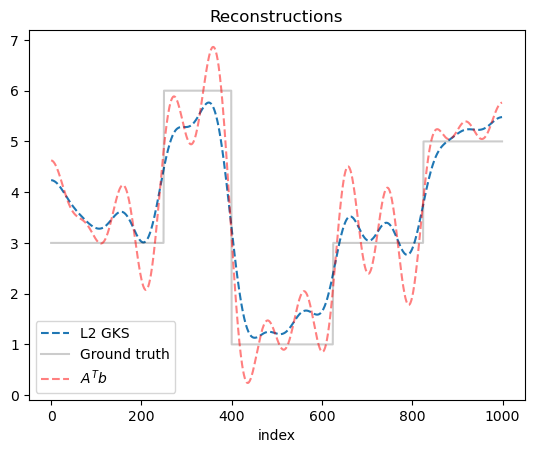

In [103]:
plt.plot(vdata['x'], label="L2 GKS", ls="--")
#plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.2)
plt.plot(A.T @ b, color="red", ls="--", alpha=0.5, label="$A^T b$")
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

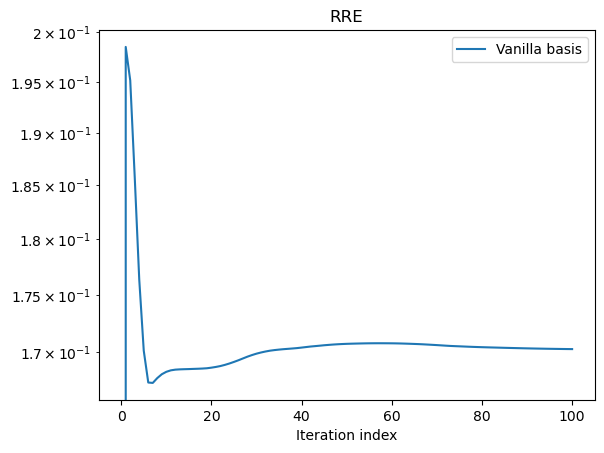

In [104]:
plt.semilogy(vdata["rre_history"], label="Vanilla basis")
#plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [30]:
plt.semilogy(vdata["lambda_history"], label="Vanilla basis")
#plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

NameError: name 'vdata' is not defined